# Netlist polarity, power for every element, and SymPy → C

1. **Netlists:** node definitions, polarity references, and p = vi for every element (Tellegen)
2. **Operators:** `=`, `==`, `<`, `<=`, `>`, `>=` in math, SymPy, and C (`sp.ccode`)
3. **Even and odd functions**
4. **Air hockey puck:** spin vs slide, the radius and height, and a wall bounce written with comparisons
5. **Generated C,** compiled with `gcc -std=c99 -Wall -Werror -pedantic` and checked against SymPy

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
import numpy as np, pandas as pd, sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
sp.init_printing(use_unicode=True)
pd.set_option("display.max_colwidth", 90)
from dgs.field_circuits import Circuit
from dgs import sympy_to_c as S

## 1. Netlist definitions and polarity

| Term | Definition |
|---|---|
| **node** | a set of wires at one voltage (one name in the netlist); **node 0** is ground, V = 0 |
| **branch / element** | `kind name a b value`: its **+ reference is node a**, − is node b |
| **v** | V(a) − V(b), the voltage of + relative to − |
| **i** | reference current flowing from a **through the element** to b, so it *enters the + terminal* |
| **p = v i** | power **absorbed** (passive sign convention). p > 0: absorbs (resistors always). p < 0: delivers |

A *negative* answer for v or i doesn't mean it's wrong. It means the real direction is opposite
to the reference you picked. **Tellegen's theorem:** the absorbed powers of all elements add up
to exactly 0, because energy is conserved. It's a free check on every circuit you solve.

In [2]:
ckt = (Circuit().V("V1", "a", "0", 10).R("R1", "a", "b", 1)
       .R("R2", "b", "0", 4).V("V2", "b", "c", 2).R("R3", "c", "0", 2))
print(ckt.paper())
display(pd.DataFrame(ckt.element_table()))
print("Tellegen: sum of absorbed power =", ckt.tellegen())

1. Label every node; node 0 is ground: a, b, c
2. Unknowns: V_a, V_b, V_c, I_V1, I_V2
3. KCL (currents leaving each node = 0), and source constraints:
     I_V1 + V_a - V_b = 0
     I_V2 - V_a + 5*V_b/4 = 0
     -I_V2 + V_c/2 = 0
     V_a = 10
     V_b - V_c = 2
4. Write as A x = b and solve (substitution, Cramer, or row reduction).
     I_V1 = -26/7
     I_V2 = 15/7
     V_a = 10
     V_b = 44/7
     V_c = 30/7
5. Check: units, s -> 0 (capacitors open, inductors short), s -> oo.


,element,kind,+ node,- node,v = V+ - V-,i (+ to - through it),p = v i (absorbed),role
0,V1,V,a,0,10,-26/7,-260/7,delivers
1,R1,R,a,b,26/7,26/7,676/49,absorbs
2,R2,R,b,0,44/7,11/7,484/49,absorbs
3,V2,V,b,c,2,15/7,30/7,absorbs
4,R3,R,c,0,30/7,15/7,450/49,absorbs


Tellegen: sum of absorbed power = 0


In [3]:
# the same thing symbolically: every quantity as an expression
Vs, R1, R2 = sp.symbols("V_s R_1 R_2", positive=True)
sym = Circuit().V("Vs", "a", "0", Vs).R("R1", "a", "b", R1).R("R2", "b", "0", R2)
display(pd.DataFrame(sym.element_table()))
print("Tellegen:", sym.tellegen())

,element,kind,+ node,- node,v = V+ - V-,i (+ to - through it),p = v i (absorbed),role
0,Vs,V,a,0,V_s,-V_s/(R_1 + R_2),-V_s**2/(R_1 + R_2),delivers
1,R1,R,a,b,R_1*V_s/(R_1 + R_2),V_s/(R_1 + R_2),R_1*V_s**2/(R_1 + R_2)**2,absorbs
2,R2,R,b,0,R_2*V_s/(R_1 + R_2),V_s/(R_1 + R_2),R_2*V_s**2/(R_1 + R_2)**2,absorbs


Tellegen: 0


## 2. `=` vs `==` and the comparison operators

In math, "=" states a fact. In C, `=` **stores** a value and `==` **asks** whether two values are
equal. SymPy keeps them apart: `Eq(a, b)` is the math equals (printed `a == b`), and
`assign_to=` makes the C assignment.

In [4]:
display(pd.DataFrame(S.operator_table(), columns=["meaning", "SymPy", "sp.ccode", "note"]))

,meaning,SymPy,sp.ccode,note
0,equal (math =),Equality,a == b,compare: is a equal to b?
1,not equal,Unequality,a != b,
2,less than,StrictLessThan,a < b,
3,less or equal,LessThan,a <= b,
4,greater than,StrictGreaterThan,a > b,
5,greater or equal,GreaterThan,a >= b,
6,assignment (store a value),assign_to=,y = a + b;,C '=' is NOT equality; mixing them up (if (x = 0)) is a classic C bug


## 3. Even and odd functions

Every function splits into even + odd: f(x) = [f(x) + f(−x)]/2 + [f(x) − f(−x)]/2. Even means
mirror-symmetric (cos, x², |x|); odd means point-symmetric (sin, x³). In physics, the
particle-in-a-box states alternate even and odd about the center, and integrals of odd
functions over symmetric limits vanish. That's why ⟨x⟩ = 0 for symmetric states.

,f(x),even part,odd part,parity
0,x**2,x**2,0,even
1,x**3,0,x**3,odd
2,cos(x),cos(x),0,even
3,sin(x),0,sin(x),odd
4,exp(x),cosh(x),sinh(x),neither
5,x**2 + x,x**2,x,neither


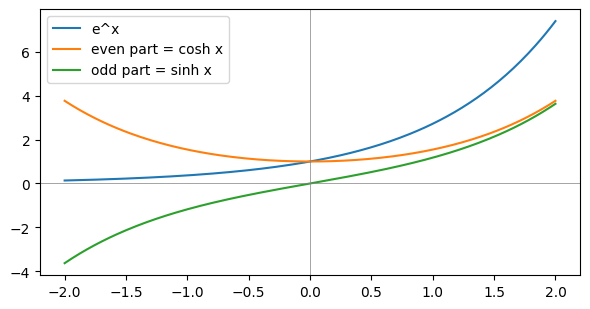

In [5]:
fs = [S.x**2, S.x**3, sp.cos(S.x), sp.sin(S.x), sp.exp(S.x), S.x**2 + S.x]
display(pd.DataFrame([(sp.sstr(f), *map(sp.sstr, S.even_odd_parts(f)), S.parity(f)) for f in fs],
                     columns=["f(x)", "even part", "odd part", "parity"]))
xs = np.linspace(-2, 2, 200); ev, od = S.even_odd_parts(sp.exp(S.x))
plt.figure(figsize=(6, 3.2))
for f, lab in [(sp.exp(S.x), "e^x"), (ev, "even part = cosh x"), (od, "odd part = sinh x")]:
    plt.plot(xs, sp.lambdify(S.x, f)(xs), label=lab)
plt.axvline(0, c="gray", lw=0.5); plt.axhline(0, c="gray", lw=0.5); plt.legend(); plt.tight_layout(); plt.show()

## 4. Air hockey puck: radius, height, and spin

Model the puck as a solid cylinder (radius R, height h, mass M). SymPy integrates r² dm:
- Spinning flat on the table, about its axis: I = ½MR². **The height drops out.**
- Flipping, about a diameter: I = M(R²/4 + h²/12). Here the height matters.

The kinetic energy is sliding plus spinning, K = ½Mv² + ½Iω².

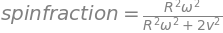

17 g puck, 3 m/s, 40 rad/s: K = 83.7 mJ, 8.6% of it in the spin


In [6]:
I = S.puck_inertia(); E = S.puck_energy()
display(sp.Eq(sp.Symbol("I_axis"), I["I_axis"]), sp.Eq(sp.Symbol("I_diameter"), I["I_diameter"]))
display(sp.Eq(sp.Symbol("K"), E["K"]), sp.Eq(sp.Symbol("spin fraction"), E["spin_fraction"]))
num = {S.M: 0.017, S.R: 0.0325, S.v: 3.0, S.w: 40.0}      # roughly a 17 g, 6.5 cm puck
print(f"17 g puck, 3 m/s, 40 rad/s: K = {float(E['K'].subs(num))*1e3:.1f} mJ, "
      f"{float(E['spin_fraction'].subs(num))*100:.1f}% of it in the spin")

⎧-e⋅vₓ  for (xₘᵢₙ ≥ -R + x ∨ xₘₐₓ ≤ R + x) ∧ (xₘᵢₙ ≥ -R + x ∨ vₓ > 0) ∧ (vₓ >  ↪
⎨                                                                              ↪
⎩ vₓ                                                     otherwise             ↪

↪ 0 ∨ vₓ < 0) ∧ (xₘₐₓ ≤ R + x ∨ vₓ < 0)
↪                                      
↪                                      

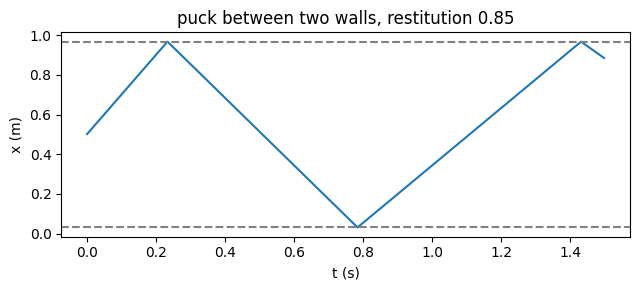

In [7]:
bounce = S.wall_bounce(); display(bounce)
step = sp.lambdify((S.px, S.vx, S.R, S.xmin, S.xmax, S.e), bounce)
xp, vxp, dt, xs_, ts = 0.5, 2.0, 1e-3, [], []
for k in range(1500):
    vxp = step(xp, vxp, 0.0325, 0.0, 1.0, 0.85); xp += vxp * dt
    xs_.append(xp); ts.append(k * dt)
plt.figure(figsize=(6.5, 3)); plt.plot(ts, xs_); plt.axhline(0.0325, ls="--", c="gray"); plt.axhline(1 - 0.0325, ls="--", c="gray")
plt.xlabel("t (s)"); plt.ylabel("x (m)"); plt.title("puck between two walls, restitution 0.85"); plt.tight_layout(); plt.show()

## 5. SymPy → C, compiled and checked

`sp.ccode` turns each expression into C. Assigned to a variable, the Piecewise becomes an
`if / else` built from `<=`, `>=`, `<`, `>`, `&&` and `||`. SymPy merged the two wall branches,
since both give −e vₓ, into one condition in a rearranged form. That's logically the same, but
it's a reminder to *test* generated code, not just read it. Without `assign_to` you'd get a
nested ternary `cond ? a : b`. gcc compiles it with every warning treated as an error,
and the numbers must match SymPy's.

In [8]:
fns = [S.c_function("puck_KE", E["K"], [S.M, S.R, S.v, S.w]),
       S.c_function("wall_vx", bounce, [S.px, S.vx, S.R, S.xmin, S.xmax, S.e])]
for f in fns: print(f)
calls = ["puck_KE(0.017, 0.0325, 3.0, 40.0)", "wall_vx(0.03, -2.0, 0.0325, 0.0, 1.0, 0.85)",
         "wall_vx(0.5, -2.0, 0.0325, 0.0, 1.0, 0.85)"]
want = [float(E["K"].subs(num)), float(step(0.03, -2.0, 0.0325, 0.0, 1.0, 0.85)), float(step(0.5, -2.0, 0.0325, 0.0, 1.0, 0.85))]
try:
    got, src = S.compile_and_run(fns, calls)
    display(pd.DataFrame({"C call": calls, "gcc result": got, "SymPy": want,
                          "match": np.isclose(got, want, rtol=1e-12)}))
except S.ToolUnavailable as err:
    print("skipped:", err)

double puck_KE(double M, double R, double v, double omega) {
    double result;
    result = (1.0/4.0)*M*(pow(R, 2)*pow(omega, 2) + 2*pow(v, 2));
    return result;
}

double wall_vx(double x, double v_x, double R, double x_min, double x_max, double e) {
    double result;
    if ((x_min >= -R + x || x_max <= R + x) && (x_min >= -R + x || v_x > 0) && (v_x > 0 || v_x < 0) && (x_max <= R + x || v_x < 0)) {
       result = -e*v_x;
    }
    else {
       result = v_x;
    }
    return result;
}



,C call,gcc result,SymPy,match
0,"puck_KE(0.017, 0.0325, 3.0, 40.0)",0.083683,0.083683,True
1,"wall_vx(0.03, -2.0, 0.0325, 0.0, 1.0, 0.85)",1.700000,1.700000,True
2,"wall_vx(0.5, -2.0, 0.0325, 0.0, 1.0, 0.85)",-2.000000,-2.000000,True
